# 18 · ReAct, plan-and-execute and reflection, as LangGraph graphs
Level L3 · Part 3 · core · ~20 min · builds on 11

## Goal
Build the three control patterns as LangGraph graphs on the same customer message, draw each graph, and count what each
one costs in model calls, tokens and dollars. Then say which pattern fits a task, and why reflection is used sparingly.

## Why it matters
Lesson 11 gave you fixed workflows: your code writes the path. Some requests have no fixed path, because the model must
look something up before it knows the next step. Without a pattern choice, a team uses one loop for every task, or adds
"let the model check its answer" everywhere, which doubles the calls and often finds nothing.

| Without choosing a pattern | With one |
|---|---|
| Easy questions cost what hard ones cost | The task's needs pick the pattern |
| A failure shows at the end as a wrong answer | Each pattern fails in a known place: a cycle, a stale plan, or an unchecked draft |
| A second pass is added everywhere, and it doubles the calls | A second pass is added only where a real check can find a problem |

**What it makes easy:** pricing a pattern from its drawing before you build. **When you don't need it:** one fixed
lookup (lesson 11 is enough).

## The idea
A pattern is a shape of graph. What differs is where the model's decisions sit: on the **diamonds**
(conditional edges), or nowhere.

- **ReAct** is a cycle: after each result the model decides whether to call a tool again or answer. Cost grows with each
  step, and a step cap ends it.
- **Plan-and-execute** is a line: the model writes the whole plan first, code runs it, and the model writes the answer.
  Calls stay fixed, but a plan made before the results can go stale.
- **Reflection** is a check after the draft: a conditional edge sends the draft back for revision only when a real
  check finds a problem. A model rereading its own draft can repeat the mistake.

Analogy: a driver with a live map who reroutes at each turn (ReAct), a trip planned before you leave (plan-and-execute),
and a proofreader with a style sheet (reflection, which needs a real rule).

## Picture
The two graphs in this lesson are drawn from the code in Steps 3 and 4, so each drawing shows exactly what runs. Read the
diamonds first: they are the only places where the model's answer changes the path. `show_graph`, a drawing helper
defined in Step 2, draws a compiled graph: blue nodes run code, amber nodes call the model. It needs internet access
(it uses the public mermaid.ink service); without it, the cell prints the same graph as text.

## Step by step

**Step 1 · setup (one model for the notebook).** `llm_setup.get_llm()` is the course's shared model setup: it reads the
key from `.env` and never shows it. `llm_replay` is a course helper, not part of LangGraph: it saves each model answer the
first time, so later runs replay the same answers offline. This notebook makes at most **five** model calls.
*You should see:* a line starting `LLM mode:`, then a setup line that ends in `API key loaded: True` on a machine with a key.

In [1]:
import sys; sys.path.insert(0, "../../..")

import llm_replay
llm_replay.start("18_control-patterns")

from llm_setup import get_llm

llm = get_llm()
PRICE_IN, PRICE_OUT = 0.25, 1.50  # USD per 1M tokens, as checked for lesson 02 on 2026-10-20

LLM mode: replay (18_control-patterns.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · the data and the one tool (no call).** `support_eval.json` is the fictional order world that lessons 07 and 08
used: 12 orders, written by hand for this course, with no personal data. Order 1003 is lost, 9 days late, with a total of
89.50 USD. The tool's arguments are checked with Pydantic, as in lesson 06, and a key the schema does not name is refused.
Every pattern below uses this same tool and this same message.
*You should see:* the first three orders as one list, then the message.

In [2]:
import json
import operator
from importlib.metadata import version
from pathlib import Path
from typing import Annotated, Literal, TypedDict

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from pydantic import BaseModel, ConfigDict, Field
from IPython.display import Image, display
from langchain_core.runnables.graph import NodeStyles
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

MODEL_STYLE = "classDef model fill:#fde68a,stroke:#b45309"  # amber: a node that calls the model
print("LangGraph", version("langgraph"))

LangGraph 1.2.16


The drawing helper comes next. It is the `show_graph` described in the Picture section.

In [3]:
def show_graph(app, model_nodes=()):
    """Draw a compiled graph (the Picture section explains the colours)."""
    text = app.get_graph().draw_mermaid(node_colors=NodeStyles(
        default="fill:#e0f2fe,stroke:#0369a1", first="fill:#f1f5f9", last="fill:#dcfce7"))
    text += f"\n{MODEL_STYLE}\n" + (f"class {','.join(model_nodes)} model\n" if model_nodes else "")
    try:
        display(Image(draw_mermaid_png(text)))
    except Exception as e:  # offline, or the service is down: the same diagram as text
        print(f"No picture ({type(e).__name__}). The same graph as Mermaid text:\n{text}")

Next, the data and the one tool that every pattern uses: `lookup_order`, which the model may ask for by name.

In [4]:
DATA = json.loads((Path("../../../data") / "support_eval.json").read_text())
ORDERS = DATA["world"]["orders"]
print(list(ORDERS.items())[:3])
MSG = "Order 1003 never arrived. Can I have my money back?"
print("message:", MSG)


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")  # a key the schema does not name is refused
    order_id: str = Field(description="The order number the customer wrote, digits only, such as 1003.")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one order: its status, days late and total."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}",
                                 "next_step": "Ask the customer for the number in the confirmation email."})


llm_tools = llm.bind_tools([lookup_order])  # the model may ask for the tool; the graph runs it
MAX_STEPS = 3  # ReAct's step cap: model calls per run, as in lesson 05

[('1001', {'status': 'delivered', 'days_late': 0, 'total': 60.0}), ('1002', {'status': 'in transit', 'days_late': 4, 'total': 45.0}), ('1003', {'status': 'lost', 'days_late': 9, 'total': 89.5})]
message: Order 1003 never arrived. Can I have my money back?


**Step 3 · ReAct: a cycle the model steers.** The agent node calls the model. If the reply asks for a tool, the graph runs
it and goes back to the agent. If the model answers, the graph stops. The `cap` node ends the cycle when the model has
used its three steps. The agent node adds its usage to `log`, so the cost table can be built at the end.

In [5]:
class ReactState(TypedDict):
    messages: Annotated[list, add_messages]  # the conversation; new messages are appended
    steps: int  # model calls made so far
    log: Annotated[list, operator.add]  # (pattern, usage) for each model call
    stop: str  # why the run ended


def react_agent(state: ReactState) -> dict:
    reply = llm_tools.invoke(state["messages"])  # the model: a tool request, or the answer
    return {"messages": [reply], "steps": state["steps"] + 1, "log": [("react", reply.usage_metadata)],
            "stop": "" if reply.tool_calls else "answered"}


def react_route(state: ReactState) -> Literal["tools", "cap", "__end__"]:
    if not state["messages"][-1].tool_calls:
        return END  # the model answered
    return "cap" if state["steps"] >= MAX_STEPS else "tools"


def react_cap(state: ReactState) -> dict:
    return {"stop": "step cap reached: the requested tool did not run"}

The graph wires these nodes together. The arrows are edges; the diamond is the conditional edge, where the route is
chosen from the model's reply. Then the graph runs on the message.

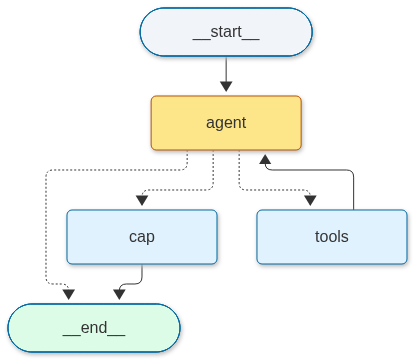

  the model asks for: lookup_order {'order_id': '1003'}
  the tool returns: {"status": "lost", "days_late": 9, "total": 89.5}
ReAct answer: I am very sorry to hear that your order 1003 never arrived. I have checked the status, and it appears the package is marked as lost.

Since it has been 9 days past the expected delivery date, I can certainly process a full refund of $89.50 for you. Would you like me to go ahead and issue that refund to your original payment method now? · stop: answered


In [6]:
g = StateGraph(ReactState)
g.add_node("agent", react_agent)
g.add_node("tools", ToolNode([lookup_order]))  # runs each tool the model asked for, and returns its result
g.add_node("cap", react_cap)
g.add_edge(START, "agent")
g.add_conditional_edges("agent", react_route, {"tools": "tools", "cap": "cap", END: END})
g.add_edge("tools", "agent")  # the cycle: the model sees each result and decides again
g.add_edge("cap", END)
react_app = g.compile()
show_graph(react_app, model_nodes=("agent",))

react_final = react_app.invoke({"messages": [HumanMessage(content=MSG)], "steps": 0, "log": [], "stop": ""})
for m in react_final["messages"][1:]:
    if isinstance(m, ToolMessage):
        print("  the tool returns:", m.content)
    elif isinstance(m, AIMessage) and m.tool_calls:
        print("  the model asks for:", m.tool_calls[0]["name"], m.tool_calls[0]["args"])
print("ReAct answer:", react_final["messages"][-1].text.strip(), "· stop:", react_final["stop"])

**Step 4 · plan-and-execute and reflection: a line, then one check.** Call 1 returns the whole plan as structured data,
before any result is known. The `execute` node runs each step with no model call. The `compose` node writes the reply
(call 2). The `check` node is code: it tests the draft against a policy rule. Only if it finds a problem does the graph go
to `revise` (call 3). Without a problem there is no third call.

In [7]:
class PlanStep(BaseModel):
    tool: str = Field(description="The tool to run. Only lookup_order exists.")
    order_id: str = Field(description="The order number for this step, digits only.")


class Plan(BaseModel):
    steps: list[PlanStep] = Field(description="The calls to make, in order. Two steps at most.")


plan_llm = llm.with_structured_output(Plan, include_raw=True)  # the parsed plan, and the raw reply for its usage
PLAN_SYSTEM = "Write the plan before any result is known: the lookups needed to answer the message."
COMPOSE_SYSTEM = "Write a two-sentence reply to the customer. Use only the facts you are given."
print("plan fields:", list(Plan.model_fields))

plan fields: ['steps']


The state carries the message, the plan, the lookup results, the draft, the check's findings and the usage log from
node to node. The plan node is call 1.

In [8]:
class PlanState(TypedDict):
    message: str
    plan: list  # the steps, as plain dicts
    facts: Annotated[list, operator.add]  # the results of the lookups
    reply: str  # the draft
    problems: list  # what the policy check found
    revised: str  # the reply after one revision, if one was needed
    log: Annotated[list, operator.add]


def plan_node(state: PlanState) -> dict:
    out = plan_llm.invoke([SystemMessage(content=PLAN_SYSTEM), HumanMessage(content=state["message"])])  # call 1
    plan = out["parsed"]
    return {"plan": [s.model_dump() for s in plan.steps], "log": [("plan", out["raw"].usage_metadata)]}


def execute_node(state: PlanState) -> dict:
    facts = []
    for s in state["plan"]:
        if s["tool"] != "lookup_order":  # code, not the model, refuses a tool the plan may not use
            raise ValueError(f"unknown tool in the plan: {s['tool']}")
        facts.append({"order_id": s["order_id"], **lookup_order.func(order_id=s["order_id"])})
    return {"facts": facts}  # no model call

The compose node writes the draft (call 2). The check node is code, so it adds no call.

In [9]:
def compose_node(state: PlanState) -> dict:
    resp = llm.invoke([SystemMessage(content=COMPOSE_SYSTEM),
                       HumanMessage(content=f"Facts: {state['facts']}\nCustomer message: {state['message']}")])  # call 2
    return {"reply": resp.text.strip(), "log": [("compose", resp.usage_metadata)]}


def policy_check(state: PlanState) -> dict:
    """External feedback: code checks the draft against policy. No model call."""
    problems = []
    text = state["reply"].lower()
    lost = any(f.get("status") == "lost" for f in state["facts"])
    if lost and "refund" in text and not any(w in text for w in ("person", "agent", "team", "approv")):
        problems.append("A refund for a lost order needs a person's approval. Say that a person will review it.")
    return {"problems": problems}

The revise node runs only when the check found a problem. Its input is the draft, the problems and the facts. The
route function sends the graph to `revise` or to the end.

In [10]:
def revise_node(state: PlanState) -> dict:
    resp = llm.invoke([SystemMessage(content=COMPOSE_SYSTEM),
                       HumanMessage(content=f"Your draft: {state['reply']}\nProblems from the policy check: "
                                            f"{state['problems']}\nCustomer message: {state['message']}\n"
                                            f"Facts: {state['facts']}\nRewrite the reply, fixing every problem.")])  # call 3
    return {"revised": resp.text.strip(), "log": [("reflect", resp.usage_metadata)]}


def route_check(state: PlanState) -> Literal["revise", "__end__"]:
    return "revise" if state["problems"] else END

Now wire the nodes into a graph, draw it, and run it on the message. `llm_replay.stop()` closes the recording after the
notebook's last model call.

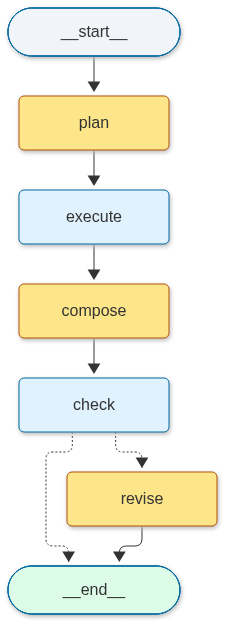

plan: [('lookup_order', '1003')]
facts: [{'order_id': '1003', 'status': 'lost', 'days_late': 9, 'total': 89.5}]
draft reply: Your order 1003 has been lost and is currently 9 days late. I have processed a refund for your total of $89.50.
check: ["A refund for a lost order needs a person's approval. Say that a person will review it."]
final reply: Your order 1003 is currently 9 days late and has been confirmed as lost. I have submitted your request for a refund of $89.50, which will now be reviewed by a member of our team for approval.


In [11]:
pg = StateGraph(PlanState)
for name, fn in [("plan", plan_node), ("execute", execute_node), ("compose", compose_node),
                 ("check", policy_check), ("revise", revise_node)]:
    pg.add_node(name, fn)
pg.add_edge(START, "plan").add_edge("plan", "execute").add_edge("execute", "compose").add_edge("compose", "check")
pg.add_conditional_edges("check", route_check, {"revise": "revise", END: END})  # reflection only on a problem
pg.add_edge("revise", END)
plan_app = pg.compile()
show_graph(plan_app, model_nodes=("plan", "compose", "revise"))

plan_final = plan_app.invoke({"message": MSG, "plan": [], "facts": [], "reply": "", "problems": [],
                              "revised": "", "log": []})
print("plan:", [(s["tool"], s["order_id"]) for s in plan_final["plan"]])
print("facts:", plan_final["facts"])
print("draft reply:", plan_final["reply"])
print("check:", plan_final["problems"] or "passed")
print("final reply:", plan_final["revised"] or plan_final["reply"])
llm_replay.stop()  # the last model call of this notebook

**Step 5 · what each pattern cost (no call).** Every model call is in a `log`, tagged by its node. The table groups them
by pattern. The reflection row is the extra cost on top of plan-and-execute; the total row adds the two together.

In [12]:
GROUP = {"react": "ReAct", "plan": "plan-and-execute", "compose": "plan-and-execute", "reflect": "reflection (extra)"}
totals: dict[str, list] = {}
for step, usage in react_final["log"] + plan_final["log"]:
    row = totals.setdefault(GROUP[step], [0, 0, 0, 0.0])
    tin, tout = usage["input_tokens"], usage["output_tokens"]
    row[0] += 1; row[1] += tin; row[2] += tout; row[3] += (tin * PRICE_IN + tout * PRICE_OUT) / 1_000_000
plan_only, extra = totals["plan-and-execute"], totals.get("reflection (extra)", [0, 0, 0, 0.0])
totals["plan+reflect total"] = [a + b for a, b in zip(plan_only, extra)]
print(f"{'pattern':20}{'calls':>6}{'in tok':>8}{'out tok':>9}{'USD':>12}")
for name, (n, tin, tout, usd) in totals.items():
    print(f"{name:20}{n:>6}{tin:>8}{tout:>9}{usd:>12.6f}")
print(f"reflection adds {100 * extra[3] / plan_only[3]:.0f}% to the cost of plan-and-execute alone")
assert llm_replay.calls() <= 5, "over the course limit of five model calls"

pattern              calls  in tok  out tok         USD
ReAct                    2     170      103    0.000197
plan-and-execute         2     280       75    0.000182
reflection (extra)       1     150       50    0.000112
plan+reflect total       3     430      125    0.000295
reflection adds 62% to the cost of plan-and-execute alone


## At work
- Teams start with the fixed workflow from lesson 11 and use ReAct only where the next step depends on what the model
  finds. Anthropic's "Building effective agents" guide makes the same order of choice. Cost per pattern is priced
  before launch → lesson 36 (cost and latency).
- Plan-and-execute and ReWOO (a variant where the plan names where each step's result goes, so the model is not called
  between steps) save model calls, but a plan can go stale. A check after each step, and a replan when it fails, is the
  usual fix → lesson 31 (failure modes and guards).
- Reflection is rare in job postings (about 2% in the market sample), and the papers on it (Reflexion, LATS, Tree of
  Thoughts) are Go deeper. Teams measure whether a second pass helps with an eval, not by feel → lesson 32 (evals in CI).

## What just happened
- ReAct made 2 calls (170 input and 103 output tokens): one tool request and one answer, at 0.000197 USD.
- Plan-and-execute made 2 calls (280 and 75 tokens) at 0.000182 USD: the plan and the reply.
- Reflection added 1 call (150 and 50 tokens), 62% on top of plan-and-execute, because the policy check found a problem.
- Each run cost under a twentieth of a cent (0.0005 USD). Plan-and-execute with reflection came to 3 calls and 0.000295 USD.

With one lookup, ReAct and plan-and-execute tie at 2 calls. With three lookups, ReAct would take 4 and plan-and-execute
still 2 (the Try it below prints these counts). Reflection adds a call only where a code check finds a problem.

## Common mistakes
1. **Passing an extra key to a tool.** The model sometimes adds a field the schema does not name. The schema refuses it,
   so the tool does not run. The cell below raises on purpose, with no model call.

In [13]:
try:
    lookup_order.invoke({"order_id": "1003", "days": 9})  # `days` is not in the schema
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

ValidationError - 1 validation error for OrderQuery


2. **Reflection with no new information.** Asking the model "check your answer" and nothing else often returns much the
   same draft. The fix is a check that adds a fact: code, a tool result or a person. The check node above is code.

3. **A plan that asks for a tool it does not have.** The model may write a step the tool list does not offer, such as
   `refund_order`. The `execute` node refuses it before any tool runs. A step that depends on a lookup's result belongs
   in ReAct, not in a plan. The cell below raises on purpose, with no model call.

In [14]:
try:
    execute_node({"plan": [{"tool": "refund_order", "order_id": "1003"}], "facts": [], "message": MSG, "reply": "",
                  "problems": [], "revised": "", "log": []})  # no such tool in this course
except Exception as error:  # print the message only: a traceback shows file paths on this machine
    print(type(error).__name__, "-", str(error).splitlines()[0])

ValueError - unknown tool in the plan: refund_order


## Try it
Write `model_calls(pattern, tool_steps=0, revisions=0)` that returns the number of model calls for a pattern, with no
model call of its own. The patterns are `"react"` (one call per tool request plus one for the answer),
`"plan"` (always two: the plan and the reply) and `"plan+reflect"` (the two, plus one call per revision).

In [15]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [16]:
def model_calls(pattern: str, tool_steps: int = 0, revisions: int = 0) -> int:
    if pattern == "react":
        return tool_steps + 1
    if pattern == "plan":
        return 2  # the plan and the reply, whatever the number of steps
    if pattern == "plan+reflect":
        return 2 + revisions
    raise ValueError(f"unknown pattern: {pattern}")


print(model_calls("react", tool_steps=1), model_calls("plan", tool_steps=1), model_calls("plan+reflect", tool_steps=1, revisions=1))  # 2 2 3
print(model_calls("react", tool_steps=3), model_calls("plan", tool_steps=3))  # 4 2

2 2 3
4 2


## Key terms
- **ReAct** — a loop in which the model picks each next step after each tool result, until it answers or a step cap stops it.
- **Plan-and-execute** — the model writes the whole plan first, code runs it, and the model writes the reply.
- **Reflection** — a check on a draft that sends it back for revision only when the check finds a problem.
- **Conditional edge** — a graph edge whose route a function chooses at run time from the state (the diamond in the picture).
- **Step cap** — a limit on model calls per run, so a loop cannot run forever.

## Recap
- ReAct is a cycle: the model picks each step after each result, and a step cap ends it. It is the most flexible.
- Plan-and-execute is a line: the calls are fixed at two, but a plan made before the results can go stale.
- Reflection is a conditional edge after a code check. It helps only with a new fact from a check, a tool or a person.
- Read the drawing before you build: the diamonds are the model's decisions, and each one has a cost.

**Interview:** "ReAct or plan-and-execute?" Strong answer: "ReAct when each next step depends on the last result.
Plan-and-execute when the steps are known from the message, because it makes fewer calls. I add reflection only where a
real check, not the model's own reading, can find a problem, and I measure whether it helps."